In [2]:
%pip install neo4j pandas matplotlib

  Using cached pandas-3.0.6-cp313-cp313-win_amd64.whl.metadata (19 kB)
  Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl.metadata (6.6 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached pandas-3.0.6-cp313-cp313-win_amd64.whl (9.6 MB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------- ----------------- 5.2/9.3 MB 25.6 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 27.4 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 21.8 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 22.2 MB/s  0:00:00
Using cached numpy-2.5.4-cp313-cp313-win_amd64.whl (12.6 MB)
   ---------------------------------------- 0

In [9]:
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "cuidadosInteligentes"

class Neo4jConnector:
    def __init__(self, uri, user, password):
        self._driver = GraphDatabase.driver(
            uri,
            auth=(user, password)
        )

neo4j_conn = Neo4jConnector(URI, USER, PASSWORD)


In [13]:
with neo4j_conn._driver.session() as session:
    resultado = session.run("RETURN 1 AS teste")
    print(resultado.single()["teste"])

1


In [20]:
import pandas as pd

with driver.session() as session:
    resultado = session.run("""
        MATCH (r:Resposta)
        RETURN
            r.Gestante_ID AS Gestante_ID,
            r.Instrumento AS Instrumento,
            r.Aplicacao_ID AS Aplicacao_ID,
            r.Pergunta_ID AS Pergunta_ID,
            r.Numero_Pergunta AS Numero_Pergunta,
            r.Valor_Resposta AS Valor_Resposta
        ORDER BY r.Instrumento, r.Gestante_ID, r.Numero_Pergunta
    """)

    dados = [dict(registro) for registro in resultado]

df = pd.DataFrame(dados)

print("Dimensões da tabela:", df.shape)
display(df.head(10))

Dimensões da tabela: (9600, 6)


,Gestante_ID,Instrumento,Aplicacao_ID,Pergunta_ID,Numero_Pergunta,Valor_Resposta
0,GEST_001,AUDIT,APLIC_001_AUDIT,AUDIT_Q01,1,Nunca
1,GEST_001,AUDIT,APLIC_001_AUDIT,AUDIT_Q02,2,1 ou 2
2,GEST_001,AUDIT,APLIC_001_AUDIT,AUDIT_Q03,3,Nunca
3,GEST_001,AUDIT,APLIC_001_AUDIT,AUDIT_Q04,4,Nunca
4,GEST_001,AUDIT,APLIC_001_AUDIT,AUDIT_Q05,5,Nunca
5,GEST_001,AUDIT,APLIC_001_AUDIT,AUDIT_Q06,6,Nunca
6,GEST_001,AUDIT,APLIC_001_AUDIT,AUDIT_Q07,7,Menos de uma vez ao mês
7,GEST_001,AUDIT,APLIC_001_AUDIT,AUDIT_Q08,8,Nunca
8,GEST_001,AUDIT,APLIC_001_AUDIT,AUDIT_Q09,9,Não
9,GEST_001,AUDIT,APLIC_001_AUDIT,AUDIT_Q10,10,Não


In [21]:
print("Quantidade de respostas por instrumento:")
display(
    df["Instrumento"]
    .value_counts()
    .rename_axis("Instrumento")
    .reset_index(name="Quantidade")
)

Quantidade de respostas por instrumento:


,Instrumento,Quantidade
0,PSQI,3600
1,OHIP14,2100
2,AUDIT,1500
3,EPDS,1500
4,FAGER,900


In [22]:
print("Valores ausentes por coluna:")
display(df.isnull().sum().rename("Valores ausentes").to_frame())

print("Quantidade de gestantes:", df["Gestante_ID"].nunique())
print("Quantidade de aplicações:", df["Aplicacao_ID"].nunique())
print("Quantidade de perguntas:", df["Pergunta_ID"].nunique())

Valores ausentes por coluna:


,Valores ausentes
Gestante_ID,0
Instrumento,0
Aplicacao_ID,0
Pergunta_ID,0
Numero_Pergunta,0
Valor_Resposta,0


Quantidade de gestantes: 150
Quantidade de aplicações: 750
Quantidade de perguntas: 64


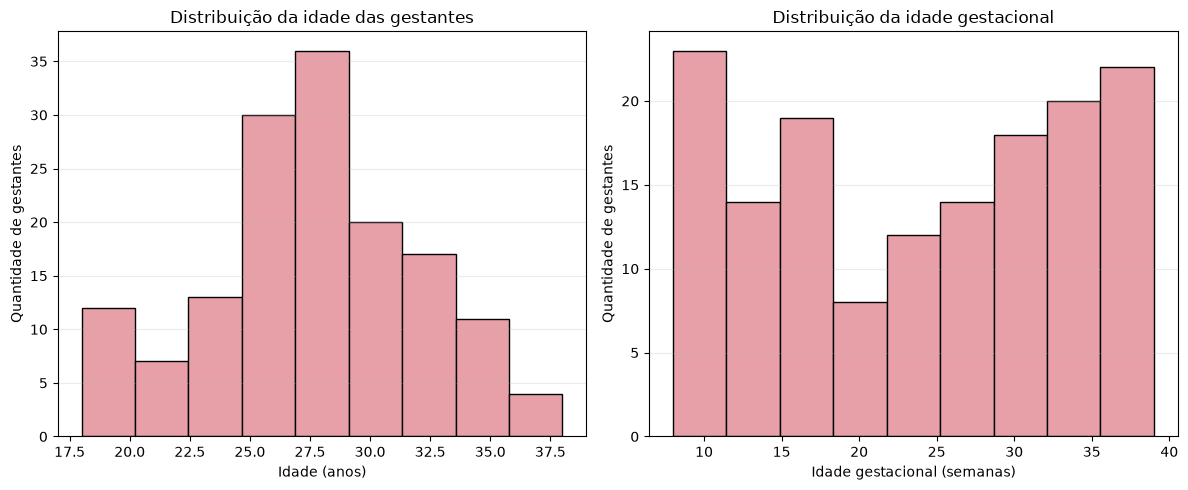

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

# Buscar informações das gestantes no Neo4j
with driver.session() as session:
    resultado = session.run("""
        MATCH (g:Gestante)
        RETURN
            g.Idade AS Idade,
            g.Idade_Gestacional_Semanas AS Idade_Gestacional_Semanas
    """)

    dados_gestantes = [dict(registro) for registro in resultado]

df_gestantes = pd.DataFrame(dados_gestantes)

# Garantir que as variáveis sejam numéricas
colunas = ["Idade", "Idade_Gestacional_Semanas"]

for coluna in colunas:
    df_gestantes[coluna] = pd.to_numeric(
        df_gestantes[coluna], errors="coerce"
    )

# Criar os dois histogramas
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))

# Histograma da idade das gestantes
eixos[0].hist(
    df_gestantes["Idade"].dropna(),
    bins="auto",
    color="#E8A0A8",
    edgecolor="black"
)
eixos[0].set_title("Distribuição da idade das gestantes")
eixos[0].set_xlabel("Idade (anos)")
eixos[0].set_ylabel("Quantidade de gestantes")
eixos[0].grid(axis="y", alpha=0.25)

# Histograma da idade gestacional
eixos[1].hist(
    df_gestantes["Idade_Gestacional_Semanas"].dropna(),
    bins="auto",
    color="#E8A0A8",
    edgecolor="black"
)
eixos[1].set_title("Distribuição da idade gestacional")
eixos[1].set_xlabel("Idade gestacional (semanas)")
eixos[1].set_ylabel("Quantidade de gestantes")
eixos[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

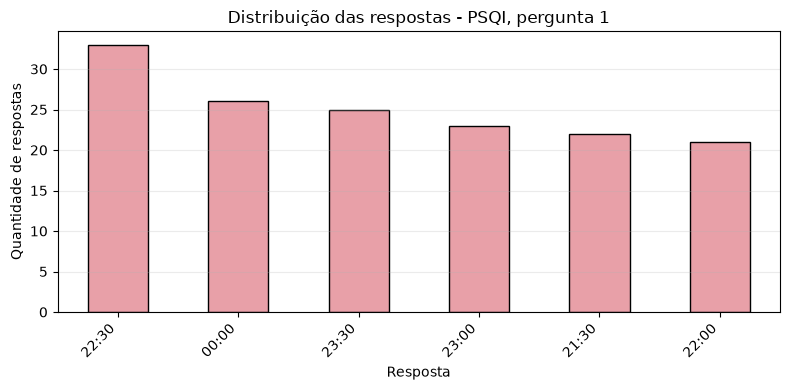

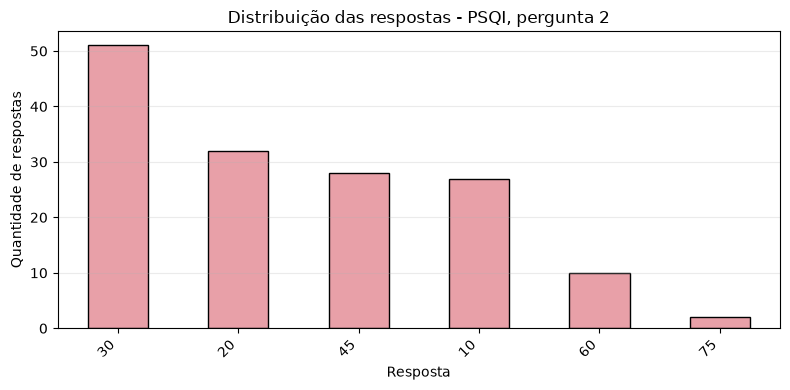

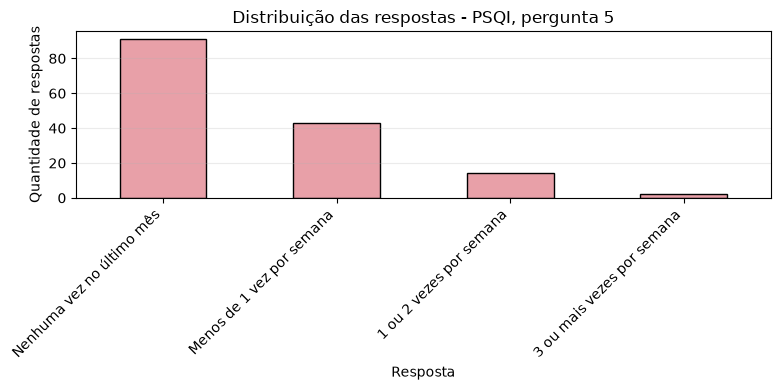

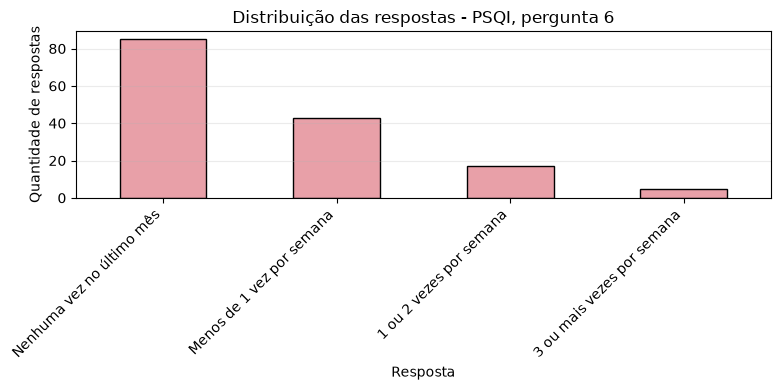

In [35]:
import matplotlib.pyplot as plt

instrumento_escolhido = "PSQI"

dados_instrumento = df[df["Instrumento"] == instrumento_escolhido]

# Mostrar somente as perguntas 1, 2, 5 e 6
perguntas_desejadas = [1, 2, 5, 6]

for numero in perguntas_desejadas:
    dados_pergunta = dados_instrumento[
        dados_instrumento["Numero_Pergunta"] == numero
    ]

    if dados_pergunta.empty:
        print(f"Pergunta {numero}: sem dados disponíveis.")
        continue

    frequencias = dados_pergunta["Valor_Resposta"].value_counts()

    plt.figure(figsize=(8, 4))
    frequencias.plot(
        kind="bar",
        color="#E8A0A8",
        edgecolor="black"
    )

    plt.title(f"Distribuição das respostas - PSQI, pergunta {numero}")
    plt.xlabel("Resposta")
    plt.ylabel("Quantidade de respostas")
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

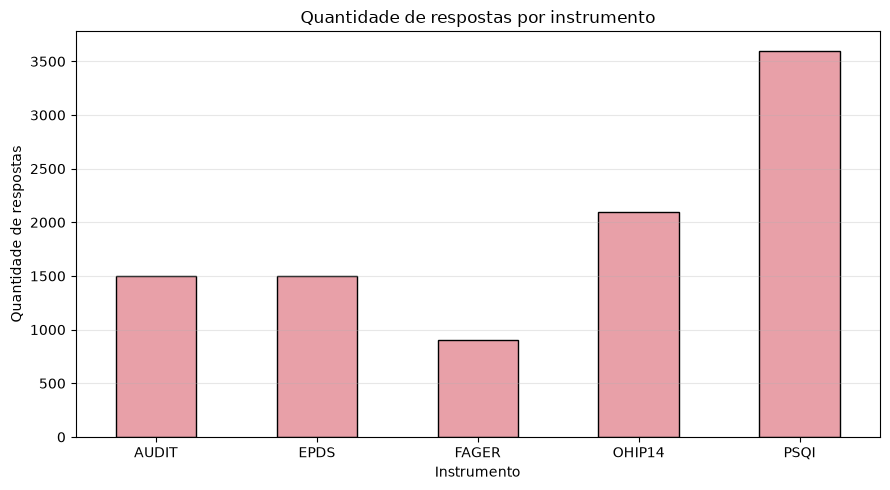

In [37]:
import matplotlib.pyplot as plt

# Contar as respostas de cada instrumento
quantidade = df.groupby("Instrumento").size()

quantidade.plot(
    kind="bar",
    figsize=(9, 5),
    color="#E8A0A8",
    edgecolor="black"
)

plt.title("Quantidade de respostas por instrumento")
plt.xlabel("Instrumento")
plt.ylabel("Quantidade de respostas")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

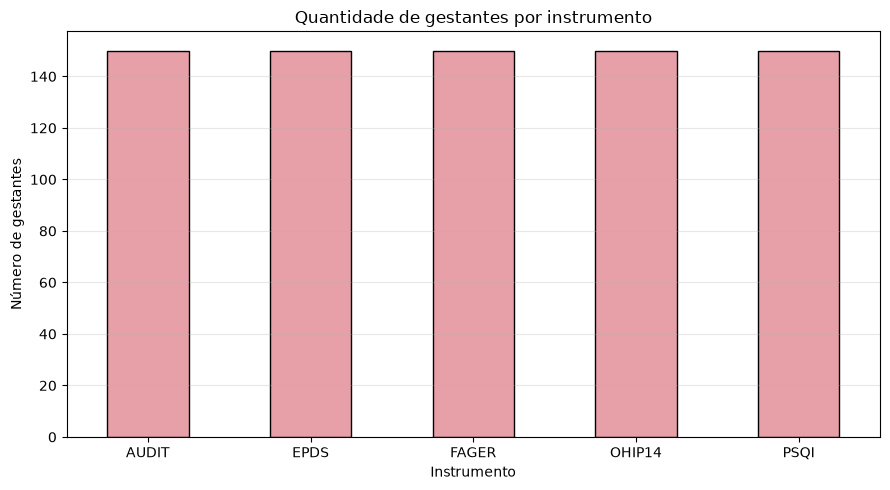

In [36]:
participantes = df.groupby("Instrumento")["Gestante_ID"].nunique()

participantes.plot(
    kind="bar",
    figsize=(9, 5),
    color="#E8A0A8",
    edgecolor="black"
)

plt.title("Quantidade de gestantes por instrumento")
plt.xlabel("Instrumento")
plt.ylabel("Número de gestantes")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()